# Part 6b: how uncertain is the headline, and what does it depend on?

The headline of 0.90 to 1.03 million units adds four pieces and reports a low and a high case. Those two numbers are bounds from different definitions (lower or upper unit counts, calibrated or unadjusted exit shares), **not a statistical interval**, and the growth piece is a scenario. A reviewer will ask two things: how wide is the range once sampling error is counted, and which assumptions move the answer?

**Sampling uncertainty** (`src/uncertainty.py`). One draw runs the three preservation pieces once more: resample the training data with replacement, refit the model, score the properties again, and draw each property's outcome as a random trial with its fitted probability. That carries both parameter uncertainty (the refit) and outcome randomness (which properties are actually rescued, or leave). Growth is kept as the three scenarios of Part 4, because their spread comes from an assumption, not from sampling.

**Sensitivity.** One assumption changed at a time, with the total recomputed.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import uncertainty as U
from viz import apply_style, SERIES, save_figure, BASELINE, INK_2, dot

apply_style()
pd.set_option("display.width", 220)
prep = U.prepare()
pt = U.point_estimates()
N = 1000
draws = U.simulate(N, prep=prep)
tot = U.totals(draws, pt)
draws.join(tot).to_csv("outputs/tables/total_draws.csv", index=False)
print(f"{N} draws; point estimates (thousand units): " + ", ".join(f"{k} {v / 1e3:,.0f}" for k, v in pt.items()))

1000 draws; point estimates (thousand units): growth 341, nhpd_lb 295, nhpd_ub 353, lihtc_adj 236, lihtc_raw 297, mort_low 28, mort_high 42, growth_low 0, growth_high 621


## 1. Sampling uncertainty by piece

For each piece, the point estimate used in the headline and the 90 percent range of the draws (5th to 95th percentile). The low column pairs the lower unit count with the calibration-adjusted exit share; the high column the upper count with the unadjusted share.

In [2]:
def q(x, p):
    return float(np.percentile(x, p))

rows = []
for name, lo_col, hi_col, lo_pt, hi_pt in (
        ("HOME and HUD subsidies not rescued", "nhpd_lb", "nhpd_ub", pt["nhpd_lb"], pt["nhpd_ub"]),
        ("LIHTC leaving monitoring", "lihtc_adj", "lihtc_raw", pt["lihtc_adj"], pt["lihtc_raw"]),
        ("Insured mortgages ending early", "mort_low", "mort_high", pt["mort_low"], pt["mort_high"])):
    rows.append({"piece": name, "headline_low": lo_pt, "headline_high": hi_pt, "low_case_5th": q(draws[lo_col], 5), "low_case_95th": q(draws[lo_col], 95),
                 "high_case_5th": q(draws[hi_col], 5), "high_case_95th": q(draws[hi_col], 95)})
pres_lo, pres_hi = pt["nhpd_lb"] + pt["lihtc_adj"] + pt["mort_low"], pt["nhpd_ub"] + pt["lihtc_raw"] + pt["mort_high"]
rows.append({"piece": "Preservation total (three pieces)", "headline_low": pres_lo, "headline_high": pres_hi, "low_case_5th": q(tot.preservation_low_case, 5),
             "low_case_95th": q(tot.preservation_low_case, 95), "high_case_5th": q(tot.preservation_high_case, 5), "high_case_95th": q(tot.preservation_high_case, 95)})
rows.append({"piece": "Total with baseline growth", "headline_low": pt["growth"] + pres_lo, "headline_high": pt["growth"] + pres_hi, "low_case_5th": q(tot.total_low_case, 5),
             "low_case_95th": q(tot.total_low_case, 95), "high_case_5th": q(tot.total_high_case, 5), "high_case_95th": q(tot.total_high_case, 95)})
unc = pd.DataFrame(rows).set_index("piece")
unc.to_csv("outputs/tables/total_uncertainty.csv")
display((unc / 1e3).round(0))
env_lo, env_hi = q(tot.total_low_case, 5), q(tot.total_high_case, 95)
print(f"\nenvelope for the total with baseline growth: {env_lo / 1e3:,.0f} to {env_hi / 1e3:,.0f} thousand units (headline {unc.loc['Total with baseline growth', 'headline_low'] / 1e3:,.0f} to {unc.loc['Total with baseline growth', 'headline_high'] / 1e3:,.0f})")
for g, name in ((pt["growth_low"], "low"), (pt["growth"], "baseline"), (pt["growth_high"], "high")):
    print(f"  growth scenario {name:8s} ({g / 1e3:,.0f} thousand): total {(g + pres_lo) / 1e3:,.0f} to {(g + pres_hi) / 1e3:,.0f} (headline definitions); with sampling error {(g + q(tot.preservation_low_case, 5)) / 1e3:,.0f} to {(g + q(tot.preservation_high_case, 95)) / 1e3:,.0f}")

,headline_low,headline_high,low_case_5th,low_case_95th,high_case_5th,high_case_95th
piece,,,,,,
HOME and HUD subsidies not rescued,295.0,353.0,287.0,303.0,343.0,362.0
LIHTC leaving monitoring,236.0,297.0,224.0,248.0,283.0,311.0
Insured mortgages ending early,28.0,42.0,24.0,32.0,38.0,46.0
Preservation total (three pieces),558.0,692.0,543.0,574.0,674.0,709.0
Total with baseline growth,900.0,1033.0,885.0,915.0,1016.0,1050.0



envelope for the total with baseline growth: 885 to 1,050 thousand units (headline 900 to 1,033)
  growth scenario low      (0 thousand): total 558 to 692 (headline definitions); with sampling error 543 to 709
  growth scenario baseline (341 thousand): total 900 to 1,033 (headline definitions); with sampling error 885 to 1,050
  growth scenario high     (621 thousand): total 1,180 to 1,313 (headline definitions); with sampling error 1,165 to 1,330


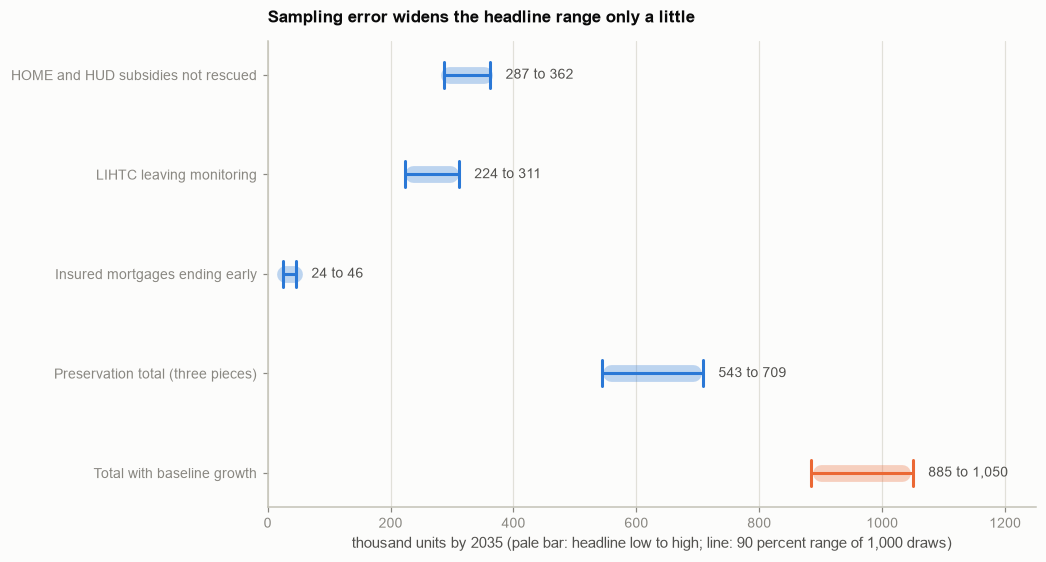

In [3]:
fig, ax = plt.subplots(figsize=(9.4, 5.0))
labels = list(unc.index)
for i, name in enumerate(labels):
    r = unc.loc[name]
    colour = SERIES[1] if name.startswith("Total") else SERIES[0]
    ax.plot([r.headline_low / 1e3, r.headline_high / 1e3], [i, i], color=colour, alpha=0.30, lw=11, solid_capstyle="round")
    lo, hi = min(r.low_case_5th, r.high_case_5th), max(r.low_case_95th, r.high_case_95th)
    ax.plot([lo / 1e3, hi / 1e3], [i, i], color=colour, lw=2.0)
    ax.plot([lo / 1e3] * 2, [i - 0.13, i + 0.13], color=colour, lw=2.0); ax.plot([hi / 1e3] * 2, [i - 0.13, i + 0.13], color=colour, lw=2.0)
    ax.annotate(f"{lo / 1e3:,.0f} to {hi / 1e3:,.0f}", (hi / 1e3, i), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1250)
ax.set_xlabel("thousand units by 2035 (pale bar: headline low to high; line: 90 percent range of 1,000 draws)")
ax.set_title("Sampling error widens the headline range only a little", fontsize=11, loc="left")
save_figure(fig, "62_total_interval", part="06_combined")
plt.show()

## 2. What the total depends on

Each row changes one assumption and recomputes the total in the low and high definitions. The change is in the midpoint of the two, against the headline.

In [4]:
sens = U.sensitivity(prep, pt)
sens.to_csv("outputs/tables/sensitivity.csv", index=False)
display(sens.assign(total_low=lambda d: d.total_low / 1e3, total_high=lambda d: d.total_high / 1e3, midpoint=lambda d: d.midpoint / 1e3, change_vs_headline=lambda d: d.change_vs_headline / 1e3).round(1))

,case,total_low,total_high,midpoint,change_vs_headline,change_pct
0,Headline (as reported),899.8,1033.0,966.4,0.0,0.0
1,Growth need: low scenario (renting keeps falling),558.4,691.5,625.0,-341.4,-35.3
2,Growth need: high scenario (renting rises),1179.6,1312.8,1246.2,279.8,29.0
3,HOME and HUD units: property total (upper boun...,957.7,1033.0,995.3,28.9,3.0
4,Rescue model: size only,908.1,1042.0,975.1,8.7,0.9
5,Rescue model: gradient boosting instead of log...,909.1,1046.0,977.6,11.2,1.2
6,Rescue chance stays at its 2022-23 level,857.4,981.2,919.3,-47.1,-4.9
7,LIHTC: unadjusted exit share in both cases,960.8,1033.0,996.9,30.5,3.2
8,Insured mortgages: low case in both,899.8,1018.6,959.2,-7.2,-0.7
9,Remove possible double count with LIHTC (183 p...,886.2,1018.8,952.5,-13.9,-1.4


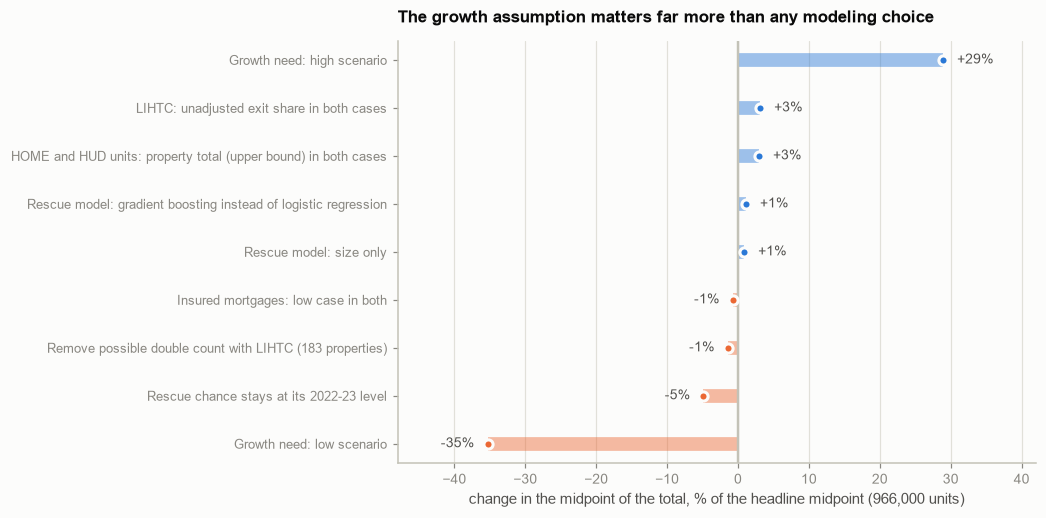

In [5]:
tor = sens[~sens.case.str.startswith("Drop") & (sens.index > 0)].sort_values("change_pct")
fig, ax = plt.subplots(figsize=(9.4, 4.6))
for i, (_, r) in enumerate(tor.iterrows()):
    colour = SERIES[1] if r.change_pct < 0 else SERIES[0]
    ax.plot([0, r.change_pct], [i, i], color=colour, lw=9, alpha=0.45, solid_capstyle="butt")
    dot(ax, r.change_pct, i, colour)
    ax.annotate(f"{r.change_pct:+.0f}%", (r.change_pct, i), xytext=(9 if r.change_pct >= 0 else -9, 0), textcoords="offset points", ha="left" if r.change_pct >= 0 else "right", va="center", fontsize=9, color=INK_2)
ax.axvline(0, color=BASELINE, lw=1.6)
ax.set_yticks(range(len(tor)), tor.case.str.replace(" (renting keeps falling)", "").str.replace(" (renting rises)", ""), fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlim(-48, 42); ax.set_xlabel("change in the midpoint of the total, % of the headline midpoint (966,000 units)")
ax.set_title("The growth assumption matters far more than any modeling choice", fontsize=11, loc="left")
save_figure(fig, "63_sensitivity", part="06_combined")
plt.show()

## Findings

**Sampling error is small next to the choices behind the headline.** Resampling the training data, refitting, and drawing random outcomes widens the total only a little: with baseline growth the headline range of 900,000 to 1,033,000 units becomes **885,000 to 1,050,000** (90 percent range of 1,000 draws around both cases). By piece, HOME and HUD subsidies not rescued 287,000 to 362,000, LIHTC leaving monitoring 224,000 to 311,000, and insured mortgages 24,000 to 46,000. The three preservation pieces together run 543,000 to 709,000.

**The growth assumption is the dominant sensitivity.** If renting keeps falling (the low scenario, no extra units needed) the total drops 35 percent to 558,000 to 692,000; if renting rises (the high scenario) it rises 29 percent to 1.18 to 1.31 million. Every modeling choice moves the midpoint by 5 percent or less. The largest is whether the rescue rate stays at its post-2021 level (-5; the HOME and HUD piece falls from 295,000 to 353,000 to 252,000 to 301,000, see Part 5h). The rest: the property total as the unit count in both cases (+3), the unadjusted LIHTC exit share (+3), gradient boosting or a size-only model for rescue (+1), the low case for insured mortgages (-1), and removing a possible double count with LIHTC (-1; 183 scored properties also hold a LIHTC subsidy placed 1996 to 2005).

**What this changes in how the headline should be read.** "Preservation is 62 to 67 percent of the total" holds under the baseline growth scenario only. Under the high scenario preservation is about 47 to 53 percent of the total; under the low scenario it is all of it. The headline number is therefore conditional on whether the long decline in renting continues, which the data cannot settle; that is a statement about demand, not about the preservation models.

**Caveats.** The draws capture sampling error and outcome randomness given the model; they do not capture a change in the process itself. The rescue rate has risen since 2021 (Part 5g and 5h); that case is the sensitivity row above, not part of the draws. Growth is not given a probability: its three scenarios are bounds. The sensitivity rows change one assumption at a time and are not additive.

Files: `src/uncertainty.py`, `outputs/tables/total_uncertainty.csv`, `sensitivity.csv`, and `total_draws.csv`.